In [3]:
import numpy as np
import pandas as pd
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

In [4]:
df = pd.read_csv('500hits.csv', encoding='latin-1')
df.head()

,PLAYER,YRS,G,AB,R,H,2B,3B,HR,RBI,BB,SO,SB,CS,BA,HOF
0,Ty Cobb,24,3035,11434,2246,4189,724,295,117,726,1249,357,892,178,0.366,1
1,Stan Musial,22,3026,10972,1949,3630,725,177,475,1951,1599,696,78,31,0.331,1
2,Tris Speaker,22,2789,10195,1882,3514,792,222,117,724,1381,220,432,129,0.345,1
3,Derek Jeter,20,2747,11195,1923,3465,544,66,260,1311,1082,1840,358,97,0.310,1
4,Honus Wagner,21,2792,10430,1736,3430,640,252,101,0,963,327,722,15,0.329,1


In [5]:
df = df.drop(columns=['PLAYER', 'CS'])
x = df.iloc[:, 0:13]
y = df.iloc[:, 13]
x_train, x_test, y_train, y_test = train_test_split(x, y, random_state=17, test_size=0.2)
x_train.shape, x_test.shape, y_train.shape, y_test.shape, x_test

((372, 13),
 (93, 13),
 (372,),
 (93,),
      YRS     G    AB     R     H   2B   3B   HR   RBI    BB    SO   SB     BA
 287   14  1888  7423  1243  1999  416   41  257   909   693  1046  243  0.269
 109   18  1988  6907  1355  2160  471   62  383  1311   913  1231  230  0.313
 235   19  2292  8198  1236  2135  366   28  338  1276   805  1069  285  0.260
 105   13  1736  6821  1390  2214  389  131  361  1537   790   369   30  0.325
 359   13  1476  5906  1313  1834  256  162  106     0   747   318  428  0.311
 ..   ...   ...   ...   ...   ...  ...  ...  ...   ...   ...   ...  ...    ...
 258   13  1654  6890  1227  2083  272  158   66     0   635   157  323  0.302
 122   17  2158  7658  1091  2048  381   24  389  1376   891  1278   68  0.267
 272   17  2035  7283  1241  2038  483   18  473  1512  1109  1745   14  0.280
 412   15  1621  5950   792  1747  354   38  127   724   349  1102  126  0.294
 354   12  1632  6366  1132  1839  322   64   98   615   804   730  407  0.289
 
 [93 rows 

In [6]:
class Node:
    def __init__(self, entropy, n_samples, counts, feature_idx=None, threshold=None, info_gain=None, left=None, right=None, value=None):

        # Decision Node
        self.feature_idx = feature_idx
        self.threshold = threshold
        self.info_gain = info_gain
        self.left = left
        self.right = right
        
        # Leaf Node
        self.value = value

        # Node Data
        self.entropy = entropy
        self.n_samples = n_samples
        self.counts = counts

class DecisionTree:
    def __init__(self, min_samples_split=2, max_depth=2, max_features=None):
        self.min_samples_split = min_samples_split
        self.max_depth = max_depth
        self.max_features = max_features

    def build_tree(self, dataset, curr_depth=0):
        x, y = dataset[:, :-1], dataset[:, -1]
        n_samples, n_features = x.shape

        if n_samples >= self.min_samples_split and curr_depth < self.max_depth:
            best_split = self.best_split(dataset, n_features)

            if best_split['info_gain'] > 0:
                left_node = self.build_tree(best_split['left_dataset'], curr_depth + 1)
                right_node = self.build_tree(best_split['right_dataset'], curr_depth + 1)

                return Node(self.entropy(y), n_samples, Counter(y), best_split['feature_idx'], best_split['threshold'], best_split['info_gain'], left_node, right_node)

        leaf_value = Counter(y).most_common(1)[0][0]
        return Node(self.entropy(y), n_samples, Counter(y), value=leaf_value)

    def best_split(self, dataset, n_features):
        best_split = {'feature_idx': None, 'threshold': None, 'info_gain': -1, 'left_dataset': None, 'right_dataset': None}

        if self.max_features is None:
            features = range(n_features)
        else:
            features = np.random.choice(n_features, self.max_features, replace=False)
            
        for feature_idx in features:
            feature_values = dataset[:, feature_idx]
            thresholds = np.unique(feature_values)

            for threshold in thresholds:
                left_dataset, right_dataset = self.split(dataset, feature_idx, threshold)

                if len(left_dataset) and len(right_dataset):
                    parent_y, left_y, right_y = dataset[:, -1], left_dataset[:, -1], right_dataset[:, -1]

                    info_gain = self.information_gain(parent_y, left_y, right_y)
                    if info_gain > best_split['info_gain']:
                        best_split['feature_idx'] = feature_idx
                        best_split['threshold'] = threshold
                        best_split['info_gain'] = info_gain
                        best_split['left_dataset'] = left_dataset
                        best_split['right_dataset'] = right_dataset

        return best_split

    def split(self, dataset, feature_idx, threshold):
        left_dataset = np.array([row for row in dataset if row[feature_idx] <= threshold])
        right_dataset = np.array([row for row in dataset if row[feature_idx] > threshold])
        return left_dataset, right_dataset

    def information_gain(self, parent_y, left_y, right_y):
        left_weight = len(left_y) / len(parent_y)
        right_weight = len(right_y) / len(parent_y)

        information_gain = self.entropy(parent_y) - (left_weight * self.entropy(left_y) + right_weight * self.entropy(right_y))
        return information_gain

    def entropy(self, y):
        entropy = 0

        class_labels = np.unique(y)
        for class_label in class_labels:
            p = len(y[y == class_label]) / len(y)
            entropy += -p * np.log2(p)

        return entropy

    def fit(self, x, y):
        dataset = np.concatenate((np.array(x), np.array(y).reshape(-1, 1)), axis=1)
        self.root = self.build_tree(dataset)

    def predict(self, x):
        return [self.predict_class(row, self.root) for row in np.array(x)]

    def predict_class(self, row, node):
        if node.value != None:
            return node.value

        feature_val = row[node.feature_idx]
        if feature_val <= node.threshold:
            return self.predict_class(row, node.left)
        else:
            return self.predict_class(row, node.right)

    def print_tree(self, node=None, depth=0, indent="|   ", feature_names=None):
        prefix = indent * depth

        if node is None:
            node = self.root
            
        node_info = f"{"    " * (3 - depth)}-Entropy: {node.entropy:.04f} | n_samples: {node.n_samples} | {node.counts}"
        
        if node.value is not None:
            print(f"{prefix}|--- class: {node.value}{node_info}")
            return

        if feature_names is None:
            feature_label = f"Feature {node.feature_idx}"
        else:
            feature_label = feature_names[node.feature_idx]

        print(f"{prefix}|--- {feature_label} <= {node.threshold}{node_info}")
        self.print_tree(node.left, depth + 1, indent, feature_names)

        print(f"{prefix}|--- {feature_label} > {node.threshold}")
        self.print_tree(node.right, depth + 1, indent, feature_names)

Score: 0.7849462365591398


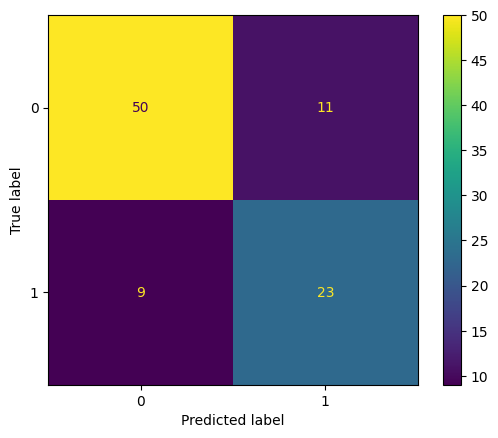

In [7]:
dtc = DecisionTree(min_samples_split=2, max_depth=2)
dtc.fit(x_train, y_train)
y_pred = dtc.predict(x_test)
print(f"Score: {np.mean(y_pred == y_test)}")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot()

In [52]:
feature_names = list(x_train.columns)
dtc.print_tree(feature_names=feature_names)

|--- H <= 2280.0            Entropy: 0.9296 | n_samples: 372 | Counter({0.0: 252, 1.0: 119, 2.0: 1})
|   |--- BA <= 0.311        Entropy: 0.5873 | n_samples: 255 | Counter({0.0: 219, 1.0: 36})
|   |   |--- class: 0.0    Entropy: 0.4921 | n_samples: 242 | Counter({0.0: 216, 1.0: 26})
|   |--- BA > 0.311
|   |   |--- class: 1.0    Entropy: 0.7793 | n_samples: 13 | Counter({1.0: 10, 0.0: 3})
|--- H > 2280.0
|   |--- H <= 2757.0        Entropy: 0.9251 | n_samples: 117 | Counter({1.0: 83, 0.0: 33, 2.0: 1})
|   |   |--- class: 1.0    Entropy: 1.0657 | n_samples: 78 | Counter({1.0: 45, 0.0: 32, 2.0: 1})
|   |--- H > 2757.0
|   |   |--- class: 1.0    Entropy: 0.1720 | n_samples: 39 | Counter({1.0: 38, 0.0: 1})
